<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/claude/gracious-brown-4ybsmj/simple_model/step5_logo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Простая интерпретируемая модель. Шаг 5: позиционный «логотип», тест и сабмит

К 61 признаку шагов 2–3б добавляем **логотип**: для каждой позиции — какая буква стоит на каждом смещении от −50 до +30
по ходу транскрипции (81 смещение × 4 буквы = 324 признака да/нет). Деревья сами находят, какие буквы на каких местах
важны и в каких сочетаниях; это ближе всего к тому, что делает CNN, но каждый признак по-прежнему читается словами
(«на −1 стоит C»). Модель: деревья глубины 6 (в эксперименте логотип раскрывается только при такой глубине).

План: признаки → обучение → плотная валидация и квантование → картинка «какие позиции важны» → тест → сабмит.
Нужны результаты шагов 1 и 3б (таблица и параметры признаков).

## 0. Настройки и данные

In [1]:
import os, sys, gzip, json, hashlib, tarfile, time, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score
try:
    import lightgbm as lgb
except ImportError:
    os.system("pip install -q lightgbm"); import lightgbm as lgb

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SPECIES = os.environ.get("EPIC_SPECIES", "jaNemVect1.1")
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
DATA_DIR = os.environ.get("EPIC_DATA_DIR", "/content/epic")
OUT_DIR = os.environ.get("EPIC_OUT_DIR", "/content/drive/MyDrive/epic_simple" if ON_COLAB else "/content/epic_simple")
BASE, FP = f"{DATA_DIR}/{SPECIES}", f"{DATA_DIR}/{SPECIES}/for_participants"
MAX_TRAIN_ROWS = int(os.environ.get("EPIC_MAX_TRAIN_ROWS", 4_000_000))   # больше строк не берём (память): лишние отрицательные отбрасываем

RAW = "https://raw.githubusercontent.com/Mitochondrion3000/epic-competiton/claude/gracious-brown-4ybsmj/simple_model/"
for mod in ("features.py", "motifs.py", "scoring.py"):
    if not os.path.exists(mod): urllib.request.urlretrieve(RAW + mod, mod)
import features as F, motifs as M, scoring as S

table = pd.read_parquet(f"{OUT_DIR}/{SPECIES}.step1_table.parquet")
meta = json.load(open(f"{OUT_DIR}/{SPECIES}.step1_meta.json"))
P = json.load(open(f"{OUT_DIR}/{SPECIES}.step3b_params.json"))
S3B = json.load(open(f"{OUT_DIR}/{SPECIES}.step3b_summary.json"))
BASE_FEATURES = P["features"]
PARAMS = {"pwm": np.array(P["pwm"]), "kmers": [tuple(k) for k in P["kmers"]], "tf": P["tf"], "wide": P["wide"], "local": P["local"]}
LOGO = F.logo_names()
ALL = BASE_FEATURES + LOGO
print(f"таблица {len(table):,} строк; признаков: {len(BASE_FEATURES)} + логотип {len(LOGO)} = {len(ALL)}")

таблица 2,493,128 строк; признаков: 61 + логотип 324 = 385


In [2]:
def download_dataset(species, data_dir):
    if os.path.isdir(f"{data_dir}/{species}"): return
    import requests
    os.makedirs(data_dir, exist_ok=True)
    rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
    f = [x for x in rec["files"] if x["key"] == f"{species}.tgz"][0]
    dst, md5 = f"{data_dir}/{species}.tgz", hashlib.md5()
    with requests.get(f["links"]["self"], stream=True, timeout=120) as r, open(dst, "wb") as fh:
        r.raise_for_status()
        for chunk in tqdm(r.iter_content(1 << 22), total=f["size"] // (1 << 22) + 1, desc=f"скачиваю {species}"):
            fh.write(chunk); md5.update(chunk)
    assert md5.hexdigest() == f.get("checksum", "md5:").split(":")[-1], "MD5 не совпал"
    with tarfile.open(dst) as tf:
        try: tf.extractall(data_dir, filter="data")
        except TypeError: tf.extractall(data_dir)
    os.remove(dst)

CODE = np.full(256, 4, np.uint8)
for i, b in enumerate("ACGT"):
    CODE[ord(b)] = CODE[ord(b.lower())] = i

def read_genome(path, keep):
    seq, low, name, chunks = {}, {}, None, []
    def flush():
        if name in keep:
            raw = np.frombuffer(b"".join(chunks), np.uint8)
            seq[name], low[name] = CODE[raw], raw >= ord("a")
    with gzip.open(path, "rb") as fh:
        for line in fh:
            if line.startswith(b">"):
                flush(); name, chunks = line[1:].split()[0].decode(), []
            elif name in keep:
                chunks.append(line.rstrip())
    flush()
    return seq, low

download_dataset(SPECIES, DATA_DIR)
tpl = pd.read_csv(f"{FP}/template.test.bed.gz", sep="\t", header=None, usecols=[0, 1, 2, 5],
                  names=["chrom", "start", "end", "strand"], dtype={"chrom": str, "strand": str})
tpl["len"] = tpl.end - tpl.start; tpl["off"] = np.r_[0, np.cumsum(tpl.len.values)[:-1]]
N_TOTAL = int(tpl.len.sum())
SEQ, LOW = read_genome(f"{BASE}/genome/genome.fa.gz", set(table.chrom) | set(tpl.chrom))
wl_train = pd.read_csv(f"{FP}/whitelist.train.bed.gz", sep="\t", header=None, usecols=[0, 1, 2], names=["chrom", "start", "end"], dtype={"chrom": str})

## 1. Признаки для обучения

61 признак считаем той же функцией, что раньше, логотип добавляем рядом. Учим на `fit`. Если строк больше
`MAX_TRAIN_ROWS` (у видов с большим геномом), случайно прореживаем отрицательные: для порядка позиций, а значит и для
обеих метрик, это почти не важно.

In [3]:
fit = table[table.split == "fit"]
if len(fit) > MAX_TRAIN_ROWS:
    pos_rows = fit[fit.y == 1]; neg_rows = fit[fit.y == 0].sample(MAX_TRAIN_ROWS - len(pos_rows), random_state=0)
    fit = pd.concat([pos_rows, neg_rows]).sort_index()
    print(f"обучающая выборка прорежена до {len(fit):,} строк")
t0 = time.time()
X = np.zeros((len(fit), len(ALL)), np.float32)
rows = np.arange(len(fit))
for c, d in tqdm(fit.assign(_r=rows).groupby("chrom", sort=False), desc="контиги", total=fit.chrom.nunique()):
    r = d._r.values
    X[r, :len(BASE_FEATURES)] = F.feature_matrix(SEQ[c], LOW[c], d.pos.values, d.strand.values, PARAMS, BASE_FEATURES)
    for st in ("+", "-"):
        m = d.strand.values == st
        if m.any(): X[r[m], len(BASE_FEATURES):] = F.logo_onehot(SEQ[c], d.pos.values[m], st)
y_fit, tot_fit = fit.y.values, fit.tot.values
print(f"матрица {X.shape} за {(time.time() - t0) / 60:.1f} мин, {X.nbytes / 1e9:.1f} ГБ")

матрица (2077779, 385) за 19.9 мин, 3.2 ГБ


## 2. Модель: деревья глубины 6

Как раньше, две модели: шанс старта (классификация) и сила старта среди стартов (`log(1 + счёт)`);
итоговый счёт = `log P(старт) + E[log(1 + счёт) | старт]`.

In [4]:
KW = dict(max_depth=6, num_leaves=64, learning_rate=0.05, n_estimators=800, min_child_samples=200,
          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
t0 = time.time()
clf = lgb.LGBMClassifier(**KW).fit(X, y_fit, feature_name=ALL)
reg = lgb.LGBMRegressor(**KW).fit(X[y_fit == 1], np.log1p(tot_fit[y_fit == 1]), feature_name=ALL)
print(f"обучено за {(time.time() - t0) / 60:.1f} мин")
del X

обучено за 4.1 мин


## 3. Плотная валидация и квантование

Те же позиции, что на шаге 3б (первые половины валидационных контигов, все позиции подряд). Предсказываем кусками,
чтобы логотип не занимал много памяти. Затем заново подбираем `alpha` квантования сабмита.

In [5]:
def predict_positions(seq, low, pos, strand, chunk=1_000_000):
    # счёт модели для позиций одной цепи одного контига; 61 признак целиком, логотип кусками
    base = F.feature_matrix(seq, low, pos, np.full(len(pos), strand), PARAMS, BASE_FEATURES)
    out = np.empty(len(pos), np.float32)
    for a in range(0, len(pos), chunk):
        b = min(a + chunk, len(pos))
        Xc = np.hstack([base[a:b], F.logo_onehot(seq, pos[a:b], strand).astype(np.float32)])
        out[a:b] = np.log(np.clip(clf.booster_.predict(Xc), 1e-12, 1)) + reg.booster_.predict(Xc)
    return out

dense_y, dense_s = [], []
lab_all = table[table.y == 1]
n_dense = 0
t0 = time.time()
for c in meta["VAL_CONTIGS"]:
    L = len(SEQ[c]); inwl = np.zeros(L, bool)
    for s, e in zip(*wl_train[wl_train.chrom == c][["start", "end"]].values.T): inwl[s:e] = True
    inwl[L // 2:] = False
    dpos = np.flatnonzero(inwl)
    if len(dpos) == 0: continue
    lab = lab_all[lab_all.chrom == c]
    tot = dict(zip(lab.pos.values * 2 + (lab.strand.values == "-"), lab.tot.values))
    for st in ("+", "-"):
        dense_s.append(predict_positions(SEQ[c], LOW[c], dpos, st))
        dense_y.append(np.array([tot.get(k, 0.0) for k in (dpos * 2 + (st == "-")).tolist()], np.float32))
    n_dense += 2 * len(dpos)
    if n_dense >= 12_000_000: break
D_S, D_Y = np.concatenate(dense_s), np.concatenate(dense_y)
print(f"плотная валидация: {len(D_Y):,} позиций, стартов {(D_Y > 0).sum():,} ({(time.time() - t0) / 60:.1f} мин)")

ALPHAS = (0.0, 0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.8)
grid = pd.DataFrame([{"alpha": a, **S.official_score(S.rank_power(D_S, a), D_Y)} for a in ALPHAS]).set_index("alpha")
grid["AUPRC / лучший"] = grid.AUPRC / grid.AUPRC.max()
ALPHA = float(grid[grid["AUPRC / лучший"] >= 0.995].Spearman.idxmax())
prev = {"AUPRC": S3B["alpha_grid"][[g["alpha"] for g in S3B["alpha_grid"]].index(S3B["alpha"])]["AUPRC"],
        "Spearman": S3B["alpha_grid"][[g["alpha"] for g in S3B["alpha_grid"]].index(S3B["alpha"])]["Spearman"]}
cmp = pd.DataFrame({"шаг 3б: 61 признак, глубина 3": prev, "шаг 5: + логотип, глубина 6": dict(grid.loc[ALPHA, ["AUPRC", "Spearman"]])}).T
display(grid.style.format("{:.4f}")); display(cmp.style.format("{:.4f}"))
print(f"alpha = {ALPHA}")

плотная валидация: 13,534,610 позиций, стартов 10,725 (17.0 мин)


,AUPRC,Spearman,AUPRC / лучший
alpha,,,
0.000000,0.0349,0.2125,0.9655
0.300000,0.0361,0.2880,1.0000
0.400000,0.0361,0.3063,0.9997
0.500000,0.0361,0.3164,0.9990
0.550000,0.0361,0.3177,0.9981
0.600000,0.0360,0.3165,0.9966
0.650000,0.0359,0.3130,0.9937
0.700000,0.0357,0.3080,0.9886
0.800000,0.0349,0.2940,0.9669


,AUPRC,Spearman
"шаг 3б: 61 признак, глубина 3",0.0244,0.2496
"шаг 5: + логотип, глубина 6",0.0361,0.3177


alpha = 0.55


**Плотная валидация (13.5 млн позиций, официальные метрики после квантования):**

| модель | AUPRC | Spearman |
|---|---|---|
| шаг 3б: 61 признак, деревья глубины 3 | 0.0244 | 0.250 |
| **шаг 5: + логотип, деревья глубины 6** | **0.0361 (+48%)** | **0.318 (+27%)** |

Квантование выбрало `alpha = 0.55`: с логотипом модель лучше различает силу стартов, поэтому сохранять различимыми
выгодно больше верхних мест.

## 4. Какие позиции и буквы важны

Для каждого признака логотипа берём его суммарный вклад в улучшение модели (gain) и раскладываем по смещениям и буквам.
Получается «логотип важности»: где вокруг старта модель смотрит на конкретные буквы. Для сравнения внизу — доля важности
всех 61 «понятного» признака по группам.

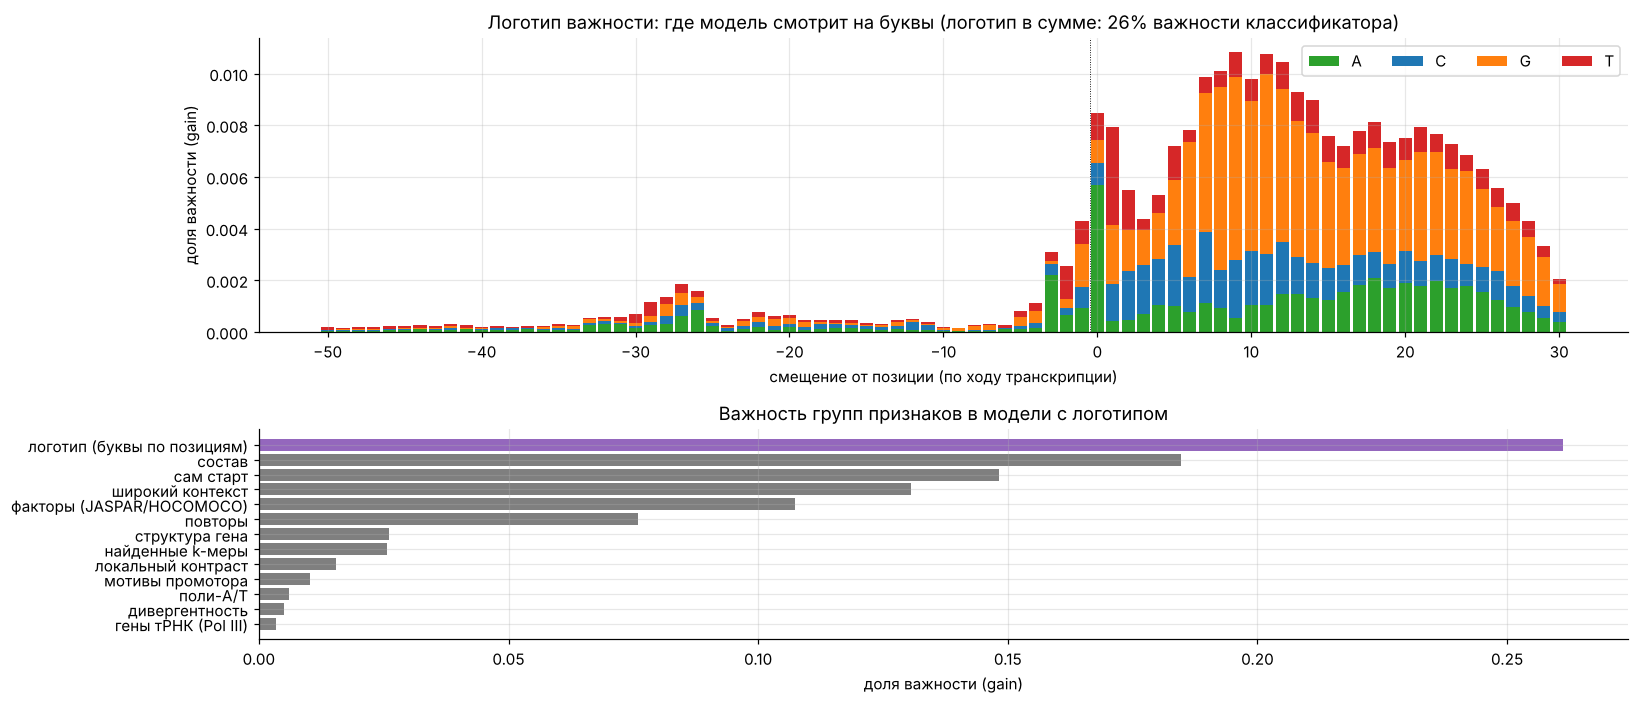

12 самых важных букв-на-позиции: b+9_G (0.7%), b+8_G (0.7%), b+11_G (0.7%), b+12_G (0.6%), b+10_G (0.6%), b+0_A (0.6%), b+7_G (0.5%), b+13_G (0.5%), b+6_G (0.5%), b+14_G (0.5%), b+21_G (0.4%), b+15_G (0.4%)


In [6]:
gain = pd.Series(clf.booster_.feature_importance("gain"), ALL)
gain = gain / gain.sum()
lg = gain[LOGO].values.reshape(-1, 4)                           # смещение x буква
offs = np.arange(F.LOGO_A, F.LOGO_B + 1)
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5), gridspec_kw={"height_ratios": [1.4, 1]})
bottom = np.zeros(len(offs))
for x, col in zip(range(4), ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
    ax[0].bar(offs, lg[:, x], bottom=bottom, color=col, label="ACGT"[x], width=0.85); bottom += lg[:, x]
ax[0].axvline(-0.5, color="k", lw=.6, ls=":")
ax[0].set(xlabel="смещение от позиции (по ходу транскрипции)", ylabel="доля важности (gain)",
          title=f"Логотип важности: где модель смотрит на буквы (логотип в сумме: {gain[LOGO].sum():.0%} важности классификатора)")
ax[0].legend(ncol=4)
grp = {}
for f in BASE_FEATURES:
    g = next((k for k, fs in F.GROUPS.items() if f in fs), "факторы (JASPAR/HOCOMOCO)" if f.startswith("tf_") else "найденные k-меры" if f.startswith("kmer_") else "другое")
    grp[g] = grp.get(g, 0) + gain[f]
grp["логотип (буквы по позициям)"] = gain[LOGO].sum()
gs = pd.Series(grp).sort_values()
ax[1].barh(gs.index, gs.values, color=["tab:purple" if "логотип" in i else "tab:gray" for i in gs.index])
ax[1].set(xlabel="доля важности (gain)", title="Важность групп признаков в модели с логотипом")
plt.tight_layout(); plt.show()
top_logo = gain[LOGO].sort_values(ascending=False).head(12)
print("12 самых важных букв-на-позиции:", ", ".join(f"{k} ({v:.1%})" for k, v in top_logo.items()))

**Где модель смотрит на буквы (сверху) и что важнее всего (снизу):**
* **Логотип в сумме — 26% важности**, больше любой другой группы. Остальное — понятные признаки: состав (18%), сам старт
  (15%), широкий контекст (13%), факторы из баз (11%), повторы (8%).
* **Сам старт (−1 и 0):** `A` на 0 и `C`/`T` на −1 — это Initiator, который у нас уже был в PWM, но здесь модель видит его
  в сочетании с остальным.
* **−3:** `A`/`T` — вероятно, удлинённый Initiator (`TCA` / `TTA`-подобный).
* **−30..−26: `A`/`T`** — небольшой, но чёткий горб ровно там, где должен стоять **TATA-бокс**. Наш признак `tata` искал
  точную последовательность `TATAWAWR` и почти ничего не находил, а логотип улавливает и неидеальные AT-богатые варианты.
* **+5..+25: `G` (оранжевое)** — самый важный участок логотипа. Начало РНК у сильных стартов богато гуанином. Возможные
  объяснения: (1) так устроена 5'-область мРНК у этого вида (GC-богатый 5'UTR); (2) особенность метода csRNA-seq, который
  ловит короткие кэпированные РНК длиной 20–60 нт: их состав влияет на то, попадут ли они в библиотеку. Наши признаки
  `gc_down` (+51..+300) и `cpg_down` смотрели дальше и грубее, поэтому этот сигнал пропускали.
* Выше −35 логотип почти не важен: там работают признаки-окна (сайты факторов, состав).

Самые важные отдельные признаки логотипа: `G` на +6..+15 и `A` на 0.

## 5. Тест и сабмит

Предсказываем все позиции шаблона (как на шаге 4), квантуем с `alpha` из раздела 3, считаем официальные метрики,
если есть ответы, и пишем файл.

In [7]:
SCORE = np.zeros(N_TOTAL, np.float32); NMASK = np.zeros(N_TOTAL, bool)
t0 = time.time()
groups = tpl.groupby(["chrom", "strand"], sort=False)
for k, ((c, st), g) in enumerate(tqdm(groups, desc="контиг × цепь", total=groups.ngroups, mininterval=30)):
    pos = np.concatenate([np.arange(s, e) for s, e in zip(g.start.values, g.end.values)])
    dst = np.concatenate([np.arange(o, o + n) for o, n in zip(g.off.values, g.len.values)])
    SCORE[dst] = predict_positions(SEQ[c], LOW[c], pos, st)
    NMASK[dst] = SEQ[c][pos] == 4
SCORE[NMASK] = -np.inf
np.save(f"{OUT_DIR}/{SPECIES}.step5_score.npy", SCORE)
print(f"тест: {N_TOTAL:,} позиций за {(time.time() - t0) / 60:.1f} мин")

SUB = S.rank_power(SCORE, ALPHA, NMASK)
sub_path = f"{OUT_DIR}/{SPECIES}.simple_model_logo.predictions.txt.gz"
S.write_submission(SUB, sub_path)
print("сабмит:", sub_path, f"({os.path.getsize(sub_path) / 1e6:.0f} МБ, строк {len(SUB):,}, alpha {ALPHA})")
assert len(SUB) == N_TOTAL and (SUB >= 0).all() and (SUB <= 1).all()

HAS_GT = os.path.exists(f"{BASE}/ground_truth/csRNA-test.txt.gz")
if HAS_GT:
    read_col = lambda p, dt: pd.read_csv(p, header=None, dtype=dt)[0].values
    GT = read_col(f"{BASE}/ground_truth/csRNA-test.txt.gz", np.float32)
    M1 = read_col(f"{BASE}/scoring/mask1-test.txt.gz", np.int8).astype(bool); M2 = read_col(f"{BASE}/scoring/mask2-test.txt.gz", np.int8).astype(bool)
    r = {h: S.official_score(SUB, GT, m) for h, m in (("half1", M1), ("half2", M2))}
    ours = {"AUPRC": np.mean([r[h]["AUPRC"] for h in r]), "Spearman": np.mean([r[h]["Spearman"] for h in r])}
    REF = {"динуклеотиды (бейзлайн организаторов)": (0.00116, 0.0361), "шаг 4: 61 признак, глубина 3": (0.0201, 0.1955),
           "InitiationNet big 96k (лучшая CNN)": (0.13165, 0.391)}
    cmp = pd.DataFrame({**{k: {"AUPRC": a, "Spearman": s} for k, (a, s) in REF.items()}, "шаг 5: + логотип, глубина 6": ours}).T
    display(cmp.style.format("{:.4f}"))
    print({h: {k: round(v, 4) for k, v in x.items()} for h, x in r.items()})
else:
    print("ответов теста нет: сабмит готов к загрузке на лидерборд (проверьте валидатором https://github.com/autosome-ru/EPIC_scoring)")
clf.booster_.save_model(f"{OUT_DIR}/{SPECIES}.step5_cls.txt"); reg.booster_.save_model(f"{OUT_DIR}/{SPECIES}.step5_reg.txt")

тест: 72,613,390 позиций за 94.1 мин


сабмит: /content/drive/MyDrive/epic_simple/jaNemVect1.1.simple_model_logo.predictions.txt.gz (60 МБ, строк 72,613,390, alpha 0.55)


,AUPRC,Spearman
динуклеотиды (бейзлайн организаторов),0.0012,0.0361
"шаг 4: 61 признак, глубина 3",0.0201,0.1955
InitiationNet big 96k (лучшая CNN),0.1316,0.3910
"шаг 5: + логотип, глубина 6",0.0292,0.2738


{'half1': {'AUPRC': 0.0369, 'Spearman': 0.2762}, 'half2': {'AUPRC': 0.0216, 'Spearman': 0.2714}}


## Итог шага 5

**Тест *Nematostella* (официальные метрики, среднее по двум половинам):**

| модель | AUPRC | Spearman |
|---|---|---|
| динуклеотиды (бейзлайн организаторов) | 0.0012 | 0.036 |
| шаг 4: 61 понятный признак, глубина 3 | 0.0201 | 0.196 |
| **шаг 5: + логотип, глубина 6** | **0.0292 (+45%)** | **0.274 (+40%)** |
| InitiationNet big (лучшая CNN) | 0.132 | 0.391 |

* Логотип дал самый большой прирост за всю серию: **AUPRC +45%, Spearman +40%**. По Spearman простая модель теперь
  на 70% пути от бейзлайна до CNN.
* Модель остаётся объяснимой: 61 признак читается словами, а логотип показывает, на какие буквы на каких местах она
  смотрит (Initiator, TATA на −30, G-богатое начало РНК). Но отдельное дерево глубины 6 читать уже трудно — это цена
  прироста. Полностью читаемой остаётся аддитивная модель из шагов 3–3б.
* Сабмит `*.simple_model_logo.predictions.txt.gz` записан (alpha 0.55).

**Что ещё можно попробовать:** расширить логотип до +60 (G-богатый участок доходит до края окна +30), добавить пары букв
(динуклеотиды) на позициях, усреднить несколько моделей с разными сидами, обучить финальную модель на всех train-контигах.